In [2]:
from copy import deepcopy
from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
import torch
from qlstm import LQLSTM
from numpy.lib.stride_tricks import sliding_window_view
from sklearn.metrics import r2_score, root_mean_squared_error
from sklearn.preprocessing import StandardScaler
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

# window, hidden, layers
CONFIGURATION = (4, 32, 1)
SEED = 42
N_QUBITS = 4
MAX_EPOCHS = 60
PATIENCE = 8
BATCH_SIZE = 256
LEARNING_RATE = 0.001

torch.set_num_threads(2)

results_dir = Path("../results/NN")
dataset = pd.read_csv(
    "../dataset/riemann_features.csv",
    usecols=lambda column: "lag" not in column.casefold(),
)
features = pd.read_csv(results_dir / "feature_ranking_full_nn.csv", index_col=0).index.tolist()[:20]
feature_counts = range(2, len(features) + 1)

train_end = int(0.8 * len(dataset))
validation_end = int(0.9 * len(dataset))
target = dataset[["distance"]].to_numpy()
target_scaler = StandardScaler().fit(target[:train_end])
scaled_target = target_scaler.transform(target).astype(np.float32)


def make_loaders(selected, window):
    values = dataset[selected].to_numpy()
    scaled = StandardScaler().fit(values[:train_end]).transform(values).astype(np.float32)
    windows = sliding_window_view(scaled, window, axis=0)[:-1].swapaxes(1, 2).copy()
    inputs = torch.from_numpy(windows)
    labels = torch.from_numpy(scaled_target[window:])
    boundaries = (0, train_end - window, validation_end - window, len(labels))
    return tuple(
        DataLoader(TensorDataset(inputs[start:end], labels[start:end]), batch_size=BATCH_SIZE)
        for start, end in zip(boundaries, boundaries[1:])
    )

## LSTM

In [4]:
class LSTM(nn.Module):
    def __init__(self, input_size, hidden_size, n_layers):
        super().__init__()
        self.recurrent = nn.LSTM(input_size, hidden_size, n_layers, batch_first=True)
        self.output = nn.Linear(hidden_size, 1)

    def forward(self, sequence):
        states, _ = self.recurrent(sequence)
        return self.output(states[:, -1])

## QLSTM

In [5]:
class QLSTM(nn.Module):
    def __init__(self, input_size, hidden_size, n_layers):
        super().__init__()
        self.recurrent = LQLSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            n_qubits=N_QUBITS,
            num_layers=n_layers,
            rotation="Y",
            batch_first=True,
        )
        self.output = nn.Linear(hidden_size, 1)

    def forward(self, sequence):
        states, _ = self.recurrent(sequence)
        return self.output(states[:, -1])

In [4]:
@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    predicted, observed = [], []
    for inputs, labels in loader:
        predicted.append(model(inputs).numpy())
        observed.append(labels.numpy())
    y_pred = target_scaler.inverse_transform(np.concatenate(predicted)).ravel()
    y_true = target_scaler.inverse_transform(np.concatenate(observed)).ravel()
    return root_mean_squared_error(y_true, y_pred), r2_score(y_true, y_pred)



def fit(model, train, validation):
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    loss_function = nn.MSELoss()
    best_rmse = float("inf")
    best_state = None
    history = []
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        squared_error = 0.0
        for inputs, labels in train:
            optimizer.zero_grad()
            loss = loss_function(model(inputs), labels)
            loss.backward()
            optimizer.step()
            squared_error += loss.item() * labels.numel()
        train_rmse = np.sqrt(squared_error / len(train.dataset)) * target_scaler.scale_[0]
        validation_rmse, _ = evaluate(model, validation)
        history.append({
            "Epoch": epoch,
            "Train RMSE": train_rmse,
            "Validation RMSE": validation_rmse,
        })
        if validation_rmse < best_rmse:
            best_rmse = validation_rmse
            best_epoch = epoch
            best_state = deepcopy(model.state_dict())
        if best_state is not None and epoch - best_epoch >= PATIENCE:
            break
    if best_state is None:
        raise ValueError("O modelo não produziu um RMSE de validação finito.")
    model.load_state_dict(best_state)
    return best_rmse, best_epoch, history


def run_experiments(configuration):
    window, hidden_size, n_layers = configuration
    models = (("LSTM", LSTM, "Features"), ("QLSTM", QLSTM, "N Features"))
    records = {name: [] for name, _, _ in models}
    history = []
    for count in feature_counts:
        train, validation, test = make_loaders(features[:count], window)
        for name, make_model, count_column in models:
            start = perf_counter()
            torch.manual_seed(SEED)
            model = make_model(count, hidden_size, n_layers)
            validation_rmse, best_epoch, learning_curve = fit(model, train, validation)
            rmse, r2 = evaluate(model, test)
            history.extend({"Model": name, "Features": count, **row} for row in learning_curve)
            records[name].append({
                "RMSE": rmse,
                "R2": r2,
                "Best Epoch": best_epoch,
                count_column: count,
                "Validation RMSE": validation_rmse,
                "Window": window,
                "Hidden Size": hidden_size,
                "Layers": n_layers,
            })
            print(f"{name} | {count} features | RMSE {rmse:.6f} | {perf_counter() - start:.1f} s", flush=True)

    tables = {name: pd.DataFrame(rows) for name, rows in records.items()}
    return tables["LSTM"], tables["QLSTM"], pd.DataFrame(history)

In [5]:
lstm_results, qlstm_results, learning_curves = run_experiments(CONFIGURATION)

lstm_results.to_csv(results_dir / "lstm_experiment_results.csv", index=False)
qlstm_results.to_csv(results_dir / "qlstm_experiment_results.csv", index=False)
learning_curves.to_csv(results_dir / "learning_curves.csv", index=False)

print(f"Resultados salvos em {results_dir.resolve()}: LSTM ({len(lstm_results)} linhas), QLSTM ({len(qlstm_results)} linhas) e curvas de aprendizado.")

LSTM | 2 features | RMSE 0.059304 | 8.3 s
QLSTM | 2 features | RMSE 0.141694 | 228.6 s
LSTM | 3 features | RMSE 0.057020 | 4.6 s
QLSTM | 3 features | RMSE 0.141774 | 233.4 s
LSTM | 4 features | RMSE 0.049227 | 4.7 s
QLSTM | 4 features | RMSE 0.119531 | 230.8 s
LSTM | 5 features | RMSE 0.044578 | 4.8 s
QLSTM | 5 features | RMSE 0.111657 | 226.0 s
LSTM | 6 features | RMSE 0.047611 | 5.0 s
QLSTM | 6 features | RMSE 0.123138 | 228.8 s
LSTM | 7 features | RMSE 0.044646 | 4.7 s
QLSTM | 7 features | RMSE 0.120201 | 320.5 s
LSTM | 8 features | RMSE 0.034828 | 4.7 s
QLSTM | 8 features | RMSE 0.112922 | 228.2 s
LSTM | 9 features | RMSE 0.036047 | 4.7 s
QLSTM | 9 features | RMSE 0.114176 | 228.4 s
LSTM | 10 features | RMSE 0.039569 | 4.7 s
QLSTM | 10 features | RMSE 0.097925 | 227.1 s
LSTM | 11 features | RMSE 0.036176 | 5.5 s
QLSTM | 11 features | RMSE 0.116584 | 227.9 s
LSTM | 12 features | RMSE 0.037134 | 4.7 s
QLSTM | 12 features | RMSE 0.102970 | 226.7 s
LSTM | 13 features | RMSE 0.033604 | 

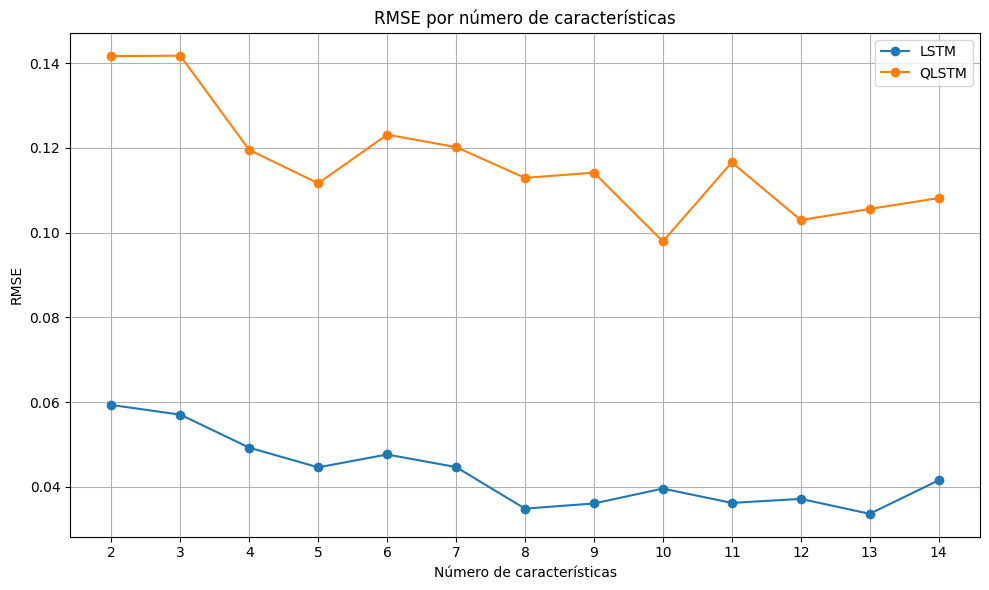

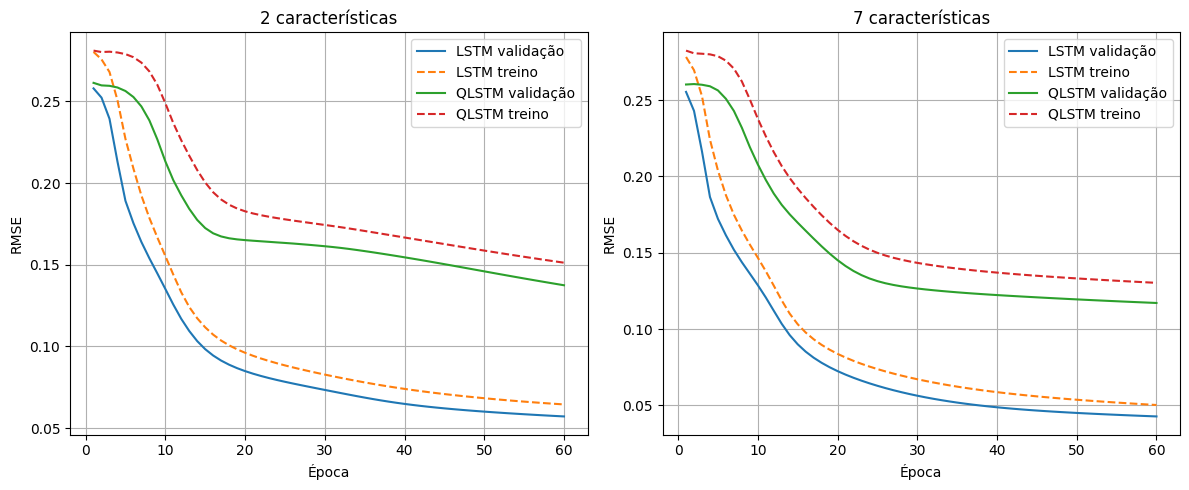

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

results_dir = Path("../results/NN")
lstm_results = pd.read_csv(results_dir / "lstm_experiment_results.csv")
qlstm_results = pd.read_csv(results_dir / "qlstm_experiment_results.csv")
learning_curves = pd.read_csv(results_dir / "learning_curves.csv")

fig, ax = plt.subplots(figsize=(10, 6))
for label, table, count_column in (
    ("LSTM", lstm_results, "Features"),
    ("QLSTM", qlstm_results, "N Features"),
):
    ordered = table.sort_values(count_column)
    ax.plot(ordered[count_column], ordered["RMSE"], marker="o", label=label)
ax.set(xlabel="Número de características", ylabel="RMSE", title="RMSE por número de características")
ax.set_xticks(sorted(set(lstm_results["Features"]) | set(qlstm_results["N Features"])))
ax.grid(True)
ax.legend()
fig.tight_layout()
fig.savefig(results_dir / "combined_results.png", dpi=160, bbox_inches="tight")
plt.show()


plot_counts = [count for count in (2, 7) if count in learning_curves["Features"].values]
fig, axes = plt.subplots(1, len(plot_counts), figsize=(6 * len(plot_counts), 5), squeeze=False)
for ax, count in zip(axes[0], plot_counts):
    history = learning_curves[learning_curves["Features"] == count]
    for name, model_history in history.groupby("Model"):
        ax.plot(model_history["Epoch"], model_history["Validation RMSE"], label=f"{name} validação")
        ax.plot(model_history["Epoch"], model_history["Train RMSE"], "--", label=f"{name} treino")
    ax.set(xlabel="Época", ylabel="RMSE", title=f"{count} características")
    ax.grid(True)
    ax.legend()
fig.tight_layout()
fig.savefig(results_dir / "learning_curves.png", dpi=160, bbox_inches="tight")
plt.show()